# Exploring datasets

In [5]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv('dataset1.csv')
df

,X1,X2,y
0,3.745401,0.314292,9.247570
1,9.507143,6.364104,16.257728
2,7.319939,3.143560,16.258844
3,5.986585,5.085707,6.359638
4,1.560186,9.075665,-9.739221
...,...,...,...
95,4.937956,3.492096,6.523018
96,5.227328,7.259557,28.761328
97,4.275410,8.971103,-4.306011
98,0.254191,8.870864,-19.500923


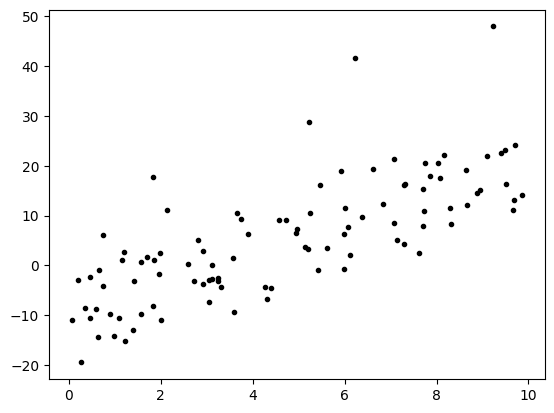

In [6]:
x1 = df['X1']
x2 = df['X2']
y = df['y']
plt.plot(x1,y,'.k')
plt.show()

In [ ]:
# create a 3D figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, y, c='blue', marker='o')
ax.view_init(elev=20,azim=60)
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('Azimutal')

plt.show()

# Normal Equation
$$\hat{\theta} = (X^TX)^{-1}(X^Ty)$$

In [ ]:
x0 = np.ones(len(x1))
X = np.c_[x0, x1, x2]
Y = np.c_[y]
thetaH = np.linalg.inv(X.T@X)@(X.T@Y)
type(thetaH)
thetaH.size
thetaH

In [ ]:
# class challenge
X = np.c_[np.ones(100), x2]
Y = np.c_[y]
thetaH = np.linalg.inv(X.T@X)@(X.T@Y)
thetaH
X

## NE-Model evaluation

In [ ]:
N = 5
x1New = np.linspace(0,10,N)
x2New = np.linspace(0,5,N)
x1NewG, x2NewG = np.meshgrid(x1New, x2New)

yH = thetaH[0]+thetaH[1]*x1NewG+thetaH[2]*x2NewG 
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, y, c='blue', marker='o')
ax.scatter(x1NewG, x2NewG,yH, c='red', marker='.')
ax.view_init(elev=20,azim=60)
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('Y')
plt.show()

In [ ]:
y0H = thetaH[0]+thetaH[1]*x1New[0]+thetaH[2]*x2New[3]
y0H

In [ ]:
N = 20
x1New = np.linspace(0,10,N)
x2New = np.linspace(0,10,N)
yM1 = thetaH[0]+thetaH[1]*x1New+thetaH[2]*x2New
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, y, c='blue', marker='o')
ax.scatter(x1New, x2New,yM1, c='red', marker='.')
#plt.plot(x1New, yM1, '.r')


In [ ]:
N = 20
x1New = np.linspace(0,10,N)
x2New = np.linspace(0,10,N)
x1NewG, x2NewG = np.meshgrid(x1New, x2New)
x1NewG

# Gradient Descent Methods

$$\theta_{new} = \theta_{old}-\eta \nabla_{\theta}$$

$$\nabla_{\theta} = \frac{2}{m}X^T(X\theta-y)$$

# Batch Gradient Descent
This method uses all data available.

In [ ]:
# bgd
df = pd.read_csv('dataset3.csv')
x1 = df['X1']
x2 = df['X2'][0:100]
y = df['y'][0:100]
plt.plot(x2, y, '.k')
plt.show()

In [ ]:
X = np.c_[np.ones_like(x2), x2]
Y = np.array(y, ndmin=2).reshape(-1,1)
#print(type(Y))
#print(Y.shape)
np.random.seed(8)
n = 100000
m = len(x1)
eta = 0.1
thetaH = np.random.rand(2,1)
thetaH

In [ ]:
for i in range(n):
    nabla = 2/m*X.T@(X@thetaH-Y)
    thetaH = thetaH-eta*nabla
print(thetaH)

In [ ]:
plt.plot(x2,y,'.k')
yH = thetaH[0]+thetaH[1]*x2
mse = np.sum(yH-y)**2/m
plt.plot(x2,yH,':r')
plt.show()
print(mse)

## MSE and model parameters evolution

In [ ]:
# bgd
df = pd.read_csv('dataset1.csv')
x1 = df['X1']
x2 = df['X2']
y = df['y']
#plt.plot(x1, y, '.k')
#plt.show()

In [ ]:
X = np.c_[np.ones_like(x1), x1]
Y = np.array(y, ndmin=2).reshape(-1,1)
#print(type(Y))
#print(Y.shape)
np.random.seed(8)
n = 500
m = len(x1)
eta = 0.01
thetaH = np.random.rand(2,1)
thetaH

In [ ]:
thetas = np.zeros((n,2))
J = np.zeros((n,1))
thetas[0] = thetaH.ravel()
for i in range(n):
    nabla = 2/m*X.T@(X@thetaH-Y)
    thetaH = thetaH-eta*nabla
    yH = thetaH[0]+thetaH[1]*x1
    mse = np.sum(yH-y)**2/m
    thetas[i] = thetaH.ravel()
    J[i] = mse
print(thetaH)

In [ ]:
plt.plot(J,'.r')
plt.show()

In [ ]:
plt.plot(thetas[:,0], '.g', label=r"$\theta_0$", alpha=0.3)
plt.plot(thetas[:,1], 'xb', label=r"$\theta_1$")
plt.legend()
plt.show()

In [ ]:
thetas[0:10,0]

# Gradient Descent Methods
## Batch Gadrient Descent

$$\theta_{new} = \theta_{old}-\eta \nabla_{\theta}$$

$$\nabla_{\theta} = \frac{2}{m} X^T(X\theta-y)$$

In [ ]:
df = pd.read_csv('dataset1.csv')
x1 = df['X1']
x2 = df.X2
y = df['y']

In [ ]:
plt.plot(x1, y, '.k')
plt.show()

In [ ]:
#BGD
# Init
X = np.c_[np.ones_like(x1), x1]
y = np.array(y, ndmin=2).reshape(-1,1)
m = len(x1)
eta = 0.05
n = 1000
np.random.seed(3)
thetaH = np.random.rand(2,1)
print(thetaH)

In [ ]:
thetaH.ravel()
2/m*X.T@(X@thetaH-y)

In [ ]:
thetas = np.zeros((n,2)) 
J = np.zeros((n,1))
nablas = np.zeros((n,2)) ##

thetas[0] = thetaH.ravel()
for i in range(n):
    nabla = 2/m*X.T@(X@thetaH-y)
    thetaH = thetaH-eta*nabla
    yH = thetaH[0]+thetaH[1]*x1
    mse = 1/m*(X@thetaH-y).T@(X@thetaH-y) ###
    J[i] = mse
    nablas[i] = nabla.ravel()
    thetas[i] = thetaH.ravel() ####
print(thetaH)

In [ ]:
plt.plot(J, 'or')
plt.show()


In [ ]:
plt.plot(nablas[:,1], 'og')
#plt.ylim([-1,1])

In [ ]:
plt.plot(thetas[:,0], 'og')
plt.plot(thetas[:,1], 'or')

In [11]:
matrix = np.c_[x1, x2, x2, 2*x2]
matrix.shape

(100, 4)